In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

In [ ]:
x_fantoma = X_fantoma.reshape(-1)

In [ ]:
def matriz_proyeccion(n, direcciones):
  res = []

  for direccion in direcciones:                                      # Por cada dirección (α, β)
    eses = []                                                        # Valores de s de esa dirección

    for i in range(n):                                               # Por cada fila
      for j in range(n):                                             # Por cada columna
        s = direccion[0] * i + direccion[1] * j                      # El s del rayo que pasa por ese píxel

        if s not in eses:                                            # Evitamos repetir rayos
          eses.append(s)

    for s in sorted(eses):                                           # Por cada rayo, de menor a mayor s
      res.append(mascara_rayo(n, direccion, s).reshape(-1))          # Agregamos su máscara vectorizada

  return np.array(res)

In [ ]:
def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                             # Inicializamos una matriz de ceros
  for i in range(0, n):                                              # Por cada fila
    for j in range(0, n):                                            # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                   # Vemos si está en el centro
        res[i, j] = 1                                                # Modificamos

  return res

In [ ]:
n=8

dir_7 = [(1,0), (0,1), (1,1), (1,-1), (2,1), (1,2), (3,1)]

A_7 = matriz_proyeccion(n, dir_7)

a)

Generamos un único vector aleatorio gaussiano y lo escalamos para construir distintos niveles de ruido. Utilizamos el mismo vector aleatorio para todos los valores de \(\sigma\), de modo que podamos comparar el efecto de aumentar la intensidad del ruido manteniendo su patrón.

In [ ]:
np.random.seed(42)

b_7 = A_7 @ x_fantoma

z = np.random.randn(len(b_7))

escala = np.sqrt(np.mean(b_7**2))

# Valores de sigma
sigmas = [0, 0.01, 0.03, 0.06, 0.10]

# Generamos el ruido y las mediciones perturbadas
ruidos = {}
b_sigma = {}

for sigma in sigmas:
    eta = sigma * escala * z
    ruidos[sigma] = eta
    b_sigma[sigma] = b_7 + eta

print("Escala:", escala)

for sigma in sigmas:
    print(f"Sigma = {sigma:.2f}")
    print("Norma del ruido:", np.linalg.norm(ruidos[sigma]))
    print("Primeras 5 mediciones:", b_sigma[sigma][:5])

Escala: 1.0963269462661418
Sigma = 0.00
Norma del ruido: 0.0
Primeras 5 mediciones: [0.  1.7 3.3 2.3 2. ]
Sigma = 0.01
Norma del ruido: 0.11076474610512202
Primeras 5 mediciones: [0.00544561 1.69848417 3.30710078 2.31669739 1.99743291]
Sigma = 0.03
Norma del ruido: 0.3322942383153661
Primeras 5 mediciones: [0.01633683 1.69545251 3.32130235 2.35009216 1.99229874]
Sigma = 0.06
Norma del ruido: 0.6645884766307322
Primeras 5 mediciones: [0.03267367 1.69090503 3.3426047  2.40018432 1.98459748]
Sigma = 0.10
Norma del ruido: 1.1076474610512201
Primeras 5 mediciones: [0.05445611 1.68484171 3.37100784 2.46697387 1.97432913]


b)

En esta celda, reconstruimos el fantoma para cada valor de \(\sigma\) mediante mínimos cuadrados usando `np.linalg.lstsq`. Luego calculamos la norma del ruido, la norma del residuo, el error relativo de reconstrucción y los valores mínimo y máximo de cada solución. Finalmente, mostramos los resultados en una tabla utilizando formato de texto.

In [ ]:
x_reconstruido_sigma = []

print(f"{'Sigma':>8} {'Norma ruido':>14} {'Norma residuo':>15} "
      f"{'Error relativo':>16} {'Mínimo':>12} {'Máximo':>12}")

for sigma in sigmas:
    b = b_sigma[sigma]

    solucion, _, _, _ = np.linalg.lstsq(A_7, b, rcond=None)

    r = b - A_7 @ solucion
    norma_ruido = np.linalg.norm(ruidos[sigma])
    norma_residuo = np.linalg.norm(r)
    err_relativo = (
        np.linalg.norm(solucion - x_fantoma)
        / np.linalg.norm(x_fantoma)
    )

    x_reconstruido_sigma.append(solucion)

    print(f"{sigma:8.2f} {norma_ruido:14.6f} {norma_residuo:15.6f} "
          f"{err_relativo:16.6f} {np.min(solucion):12.6f} "
          f"{np.max(solucion):12.6f}")

   Sigma    Norma ruido   Norma residuo   Error relativo       Mínimo       Máximo
    0.00       0.000000        0.000000         0.000000    -0.000000     0.800000
    0.01       0.110765        0.068355         0.021488    -0.016268     0.802564
    0.03       0.332294        0.205064         0.064464    -0.048803     0.807692
    0.06       0.664588        0.410128         0.128928    -0.097606     0.815384
    0.10       1.107647        0.683546         0.214881    -0.162676     0.825641


Representamos las reconstrucciones como matrices de tamaño 8x8. Utilizamos los mismos valores mínimo y máximo de escala de grises en todos los paneles para que las imágenes sean comparables visualmente y podamos observar cómo cambia la reconstrucción al aumentar sigma.

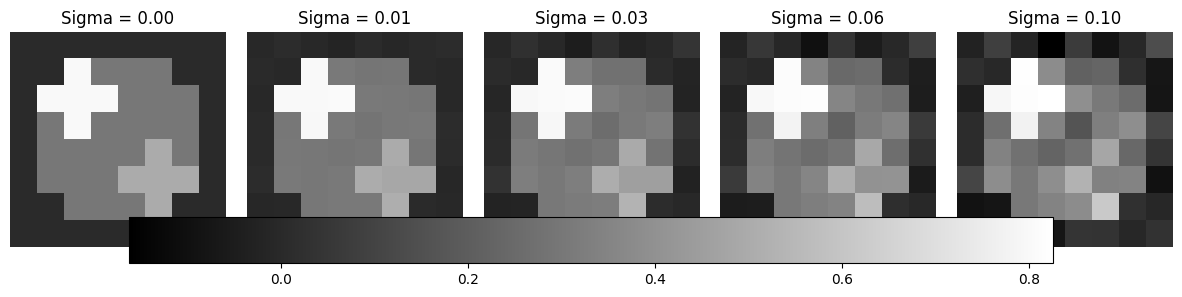

In [ ]:

# Convertimos los vectores reconstruidos en matrices 8x8
x_recon_matrix = [
    x.reshape(n, n) for x in x_reconstruido_sigma
]

# Misma escala de color para todas las reconstrucciones
vmin = min(img.min() for img in x_recon_matrix)
vmax = max(img.max() for img in x_recon_matrix)

fig, ax = plt.subplots(1, 5, figsize=(15, 4))

for i, sigma in enumerate(sigmas):
    im = ax[i].imshow(
        x_recon_matrix[i],
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[i].set_title(f"Sigma = {sigma:.2f}")
    ax[i].axis("off")

fig.colorbar(im, ax=ax.ravel().tolist(), location="bottom", shrink=1.0)
fig.subplots_adjust(bottom=0.15, wspace=0.1)
plt.show()


c)

### Análisis de los resultados

Al aumentar $\sigma$, aumenta el error relativo de reconstrucción: pasa de 0.0215 para $\sigma=0.01$ a 0.0645 para $\sigma=0.03$, 0.129 para $\sigma=0.06$ y 0.215 para $\sigma=0.10$. El error crece proporcionalmente a $\sigma$ porque se utiliza el mismo vector aleatorio para generar todos los niveles de ruido, variando únicamente su escala. Como la reconstrucción por mínimos cuadrados es lineal en los datos, la diferencia $\hat{x}_\sigma-x_{\text{fantoma}}$ depende linealmente del ruido agregado y, por lo tanto, también es proporcional a $\sigma$.

Sin ruido, $b_7$ pertenece al espacio columna de $A_7$, por lo que existe una solución exacta y el residuo es nulo. Al agregar ruido, el vector observado deja de pertenecer, en general, a ese espacio. El ruido puede descomponerse en una componente que pertenece a $\operatorname{Col}(A_7)$ y otra ortogonal a dicho espacio. La reconstrucción absorbe la primera componente, que modifica la solución obtenida, mientras que la segunda queda en el residuo. Por eso, la norma del residuo es menor que la norma del ruido agregado, como se observa en la tabla.


El método de mínimos cuadrados sin restricciones busca minimizar el error cuadrático, pero no impone que las componentes de la solución sean no negativas. La perturbación introducida por el ruido se distribuye entre los píxeles de la reconstrucción y puede tener signos positivos o negativos. Como algunos píxeles del fantoma original tienen valor cero, una perturbación negativa en esos píxeles puede producir valores negativos en la solución reconstruida. Del mismo modo, una perturbación positiva puede generar valores superiores al máximo original del fantoma. Estos resultados muestran que la reconstrucción por mínimos cuadrados sin restricciones no garantiza soluciones físicamente válidas.